In [144]:
import dask.dataframe as dd
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
from statsmodels.tsa.seasonal import STL
import seaborn as sns
import numpy as np
from datetime import timedelta
from sklearn.preprocessing import LabelEncoder
import category_encoders as ce
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
from sklearn.model_selection import train_test_split
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score,root_mean_squared_error
import xgboost as xgb
from sklearn.preprocessing import StandardScaler

In [145]:
df = pd.read_csv('routes.csv')

In [146]:
columns_order = [
    "BOOKING_ID", "ITEM_NO", "ROUTE", "AIRLINE", "ADULT", "CHILD", "INFANT", 
    "COST", "PRICE", "BOOKING_CLASS", "CABIN_CLASS", "FARE_TYPE", 
    "BOOKED_DATE", "DEP_DATE", "DES_DATE", "DAYS_IN_BETWEEN"
]

df = df[columns_order]
df.head()

,BOOKING_ID,ITEM_NO,ROUTE,AIRLINE,ADULT,CHILD,INFANT,COST,PRICE,BOOKING_CLASS,CABIN_CLASS,FARE_TYPE,BOOKED_DATE,DEP_DATE,DES_DATE,DAYS_IN_BETWEEN
0,10006,1.0,LHR -> MUC -> MUC -> DEL -> DEL -> FRA -> FRA ...,LH,2.0,0.0,0.0,825.08,833.38,K,Economy,PUB,2018-11-15,2019-09-01,2019-09-09,290
1,10007,1.0,LHR -> DEL -> DEL -> LHR,BA,2.0,0.0,0.0,1444.84,1487.94,N,Economy,PUB,2018-11-15,2019-08-20,2019-08-29,278
2,10012,1.0,LHR -> DEL -> DEL -> LHR,BA,2.0,0.0,0.0,1986.64,2043.94,T,PremiumEconomy,PVT,2018-11-16,2019-08-20,2019-08-29,277
3,10013,1.0,LHR -> DEL -> DEL -> LHR,BA,2.0,0.0,0.0,1235.04,1267.64,Q,Economy,PUB,2018-11-19,2019-01-01,2019-01-10,43
4,10014,1.0,LHR -> FRA -> FRA -> DEL -> DEL -> FRA -> FRA ...,LH,2.0,0.0,0.0,1094.28,1116.78,V,Economy,PUB,2018-11-19,2019-10-19,2019-10-28,334


In [147]:
df = df.apply(lambda col: col.str.lower() if col.dtype == 'object' else col)

In [148]:
# Group by ROUTE and aggregate min and max dates
date_ranges = df.groupby('ROUTE').agg(
    BOOKED_DATE_MIN=('BOOKED_DATE', 'min'),
    BOOKED_DATE_MAX=('BOOKED_DATE', 'max'),
    DEP_DATE_MIN=('DEP_DATE', 'min'),
    DEP_DATE_MAX=('DEP_DATE', 'max')
).reset_index()

print(date_ranges)

                                                   ROUTE BOOKED_DATE_MIN  \
0                                             aam -> jnb      2024-06-24   
1      abr -> msp -> msp -> atl -> atl -> msy -> bna ...      2024-01-12   
2      abr -> msp -> msp -> sjc -> sna -> msp -> msp ...      2024-01-12   
3      abz -> ams -> ams -> ath -> ath -> cfu -> cfu ...      2022-06-04   
4      abz -> ams -> ams -> ath -> fco -> ams -> ams ...      2023-08-26   
...                                                  ...             ...   
31032                           zrh -> rho -> rho -> zrh      2021-07-19   
31033  zrh -> sin -> sin -> mel -> syd -> sin -> sin ...      2020-03-15   
31034                           zrh -> skg -> skg -> zrh      2021-07-19   
31035                           zth -> ath -> ath -> her      2021-03-01   
31036                                         zth -> cfu      2022-06-10   

      BOOKED_DATE_MAX DEP_DATE_MIN DEP_DATE_MAX  
0          2024-06-24   2025-10-22   

In [149]:
df.head()

,BOOKING_ID,ITEM_NO,ROUTE,AIRLINE,ADULT,CHILD,INFANT,COST,PRICE,BOOKING_CLASS,CABIN_CLASS,FARE_TYPE,BOOKED_DATE,DEP_DATE,DES_DATE,DAYS_IN_BETWEEN
0,10006,1.0,lhr -> muc -> muc -> del -> del -> fra -> fra ...,lh,2.0,0.0,0.0,825.08,833.38,k,economy,pub,2018-11-15,2019-09-01,2019-09-09,290
1,10007,1.0,lhr -> del -> del -> lhr,ba,2.0,0.0,0.0,1444.84,1487.94,n,economy,pub,2018-11-15,2019-08-20,2019-08-29,278
2,10012,1.0,lhr -> del -> del -> lhr,ba,2.0,0.0,0.0,1986.64,2043.94,t,premiumeconomy,pvt,2018-11-16,2019-08-20,2019-08-29,277
3,10013,1.0,lhr -> del -> del -> lhr,ba,2.0,0.0,0.0,1235.04,1267.64,q,economy,pub,2018-11-19,2019-01-01,2019-01-10,43
4,10014,1.0,lhr -> fra -> fra -> del -> del -> fra -> fra ...,lh,2.0,0.0,0.0,1094.28,1116.78,v,economy,pub,2018-11-19,2019-10-19,2019-10-28,334


In [150]:
df['BOOKED_DATE'] = pd.to_datetime(df['BOOKED_DATE'])
df['BOOKED_YEAR'] = df['BOOKED_DATE'].dt.year
df['BOOKED_MONTH'] = df['BOOKED_DATE'].dt.month
df['BOOKED_DAY'] = df['BOOKED_DATE'].dt.day
df['DEP_DATE'] = pd.to_datetime(df['DEP_DATE'])
df['DEP_YEAR'] = df['DEP_DATE'].dt.year
df['DEP_MONTH'] = df['DEP_DATE'].dt.month
df['DEP_DAY'] = df['DEP_DATE'].dt.day
df['DES_DATE'] = pd.to_datetime(df['DES_DATE'])
df['DES_YEAR'] = df['DES_DATE'].dt.year
df['DES_MONTH'] = df['DES_DATE'].dt.month
df['DES_DAY'] = df['DES_DATE'].dt.day
df['DEP_DES_DAYS'] = (df['DES_DATE'] - df['DEP_DATE']).dt.days
df['DAY_OF_WEEK'] = df['DEP_DATE'].dt.dayofweek

In [151]:
df['TOTAL_PASSENGERS'] = df['ADULT'] + df['CHILD'] + df['INFANT']
df['NEW_DEP_DATE'] = df['DEP_YEAR'].astype(str) + '_' + df['DEP_MONTH'].astype(str) + '_' + df['DEP_DAY'].astype(str)
df['NEW_DES_DATE'] = df['DES_YEAR'].astype(str) + '_' + df['DES_MONTH'].astype(str) + '_' + df['DES_DAY'].astype(str)
df['NEW_BOOKED_DATE'] = df['BOOKED_YEAR'].astype(str) + '_' + df['BOOKED_MONTH'].astype(str) + '_' + df['BOOKED_DAY'].astype(str)
df['BCLASS_DEP_DATE'] = df['BOOKING_CLASS'].astype(str) + '_' + df['DEP_DATE'].astype(str)
df['AIRLINE_ROUTE_BCLASS_CCLASS'] = df['AIRLINE'].astype(str) + '_' + df['ROUTE'].astype(str) + '_' + df['BOOKING_CLASS'].astype(str) + '_' + df['CABIN_CLASS'].astype(str)
df['BOOKING_CLASS_DAYS_IN_BETWEEN'] = df['BOOKING_CLASS'].astype(str) + '_' + df['DAYS_IN_BETWEEN'].astype(str)
df['DEP_MONTH_ROUTE'] = df['DEP_MONTH'].astype(str) + '_' + df['ROUTE'].astype(str)
df['MONTHROUTE_BCLASSDAYS'] = df['DEP_MONTH_ROUTE'].astype(str) + '_' + df['BOOKING_CLASS_DAYS_IN_BETWEEN'].astype(str)
df['TOTALPASSENGERS_MONTHROUTE_BCLASSDAYS'] = df['TOTAL_PASSENGERS'].astype(str) + '_' + df['MONTHROUTE_BCLASSDAYS'].astype(str)
df['TOTALPASSENGERS_BOOKINGCLASS_CCLASS_ROUTE'] = df['TOTAL_PASSENGERS'].astype(str) + '_' + df['BOOKING_CLASS'].astype(str) + '_' + df['CABIN_CLASS'].astype(str) + '_' + df['ROUTE'].astype(str)


In [152]:
columns_to_check = ['BOOKING_ID', 'ITEM_NO','ROUTE','DES_DATE','AIRLINE','ADULT','CHILD','INFANT','COST','PRICE','BOOKING_CLASS','CABIN_CLASS','FARE_TYPE','BOOKED_DATE','DEP_DATE','DAYS_IN_BETWEEN'
                    ,'TOTAL_PASSENGERS', 'BCLASS_DEP_DATE', 'AIRLINE_ROUTE_BCLASS_CCLASS', 'TOTALPASSENGERS_MONTHROUTE_BCLASSDAYS', 'TOTALPASSENGERS_BOOKINGCLASS_CCLASS_ROUTE'
]

# Calculate the sum of unique values for each column
unique_values_sum = {col: df[col].nunique() for col in columns_to_check}

# Display the sum of unique values for each column
unique_values_sum


{'BOOKING_ID': 232658,
 'ITEM_NO': 149,
 'ROUTE': 31037,
 'DES_DATE': 2301,
 'AIRLINE': 199,
 'ADULT': 12,
 'CHILD': 7,
 'INFANT': 4,
 'COST': 204662,
 'PRICE': 269613,
 'BOOKING_CLASS': 40,
 'CABIN_CLASS': 5,
 'FARE_TYPE': 5,
 'BOOKED_DATE': 1938,
 'DEP_DATE': 2287,
 'DAYS_IN_BETWEEN': 612,
 'TOTAL_PASSENGERS': 13,
 'BCLASS_DEP_DATE': 44919,
 'AIRLINE_ROUTE_BCLASS_CCLASS': 74983,
 'TOTALPASSENGERS_MONTHROUTE_BCLASSDAYS': 632083,
 'TOTALPASSENGERS_BOOKINGCLASS_CCLASS_ROUTE': 98939}

In [153]:
target_features = ['ROUTE', 'AIRLINE', 'NEW_DEP_DATE', 'NEW_DES_DATE', 'NEW_BOOKED_DATE', 'BCLASS_DEP_DATE', 'AIRLINE_ROUTE_BCLASS_CCLASS', 
                   'TOTALPASSENGERS_MONTHROUTE_BCLASSDAYS', 'TOTALPASSENGERS_BOOKINGCLASS_CCLASS_ROUTE'
            ]

label_features = ['CABIN_CLASS', 'BOOKING_CLASS', 'FARE_TYPE']

# Create a TargetEncoder instance with the columns to encode
encoder = ce.TargetEncoder(cols=target_features)

# Fit and transform the DataFrame
df_encoded = encoder.fit_transform(df[target_features], df['COST'])

# Replace original features with encoded features
df[target_features] = df_encoded

label_encoders = {}
for feature in label_features:
    le = LabelEncoder()
    df[feature] = le.fit_transform(df[feature])
    label_encoders[feature] = le

In [154]:
df.head()

,BOOKING_ID,ITEM_NO,ROUTE,AIRLINE,ADULT,CHILD,INFANT,COST,PRICE,BOOKING_CLASS,...,NEW_DEP_DATE,NEW_DES_DATE,NEW_BOOKED_DATE,BCLASS_DEP_DATE,AIRLINE_ROUTE_BCLASS_CCLASS,BOOKING_CLASS_DAYS_IN_BETWEEN,DEP_MONTH_ROUTE,MONTHROUTE_BCLASSDAYS,TOTALPASSENGERS_MONTHROUTE_BCLASSDAYS,TOTALPASSENGERS_BOOKINGCLASS_CCLASS_ROUTE
0,10006,1.0,1628.655639,1637.352288,2.0,0.0,0.0,825.08,833.38,20,...,1638.274789,1638.274789,1671.254351,1638.274789,1638.274789,k_290,9_lhr -> muc -> muc -> del -> del -> fra -> fr...,9_lhr -> muc -> muc -> del -> del -> fra -> fr...,1638.274789,1638.274789
1,10007,1.0,1789.973026,1986.574380,2.0,0.0,0.0,1444.84,1487.94,23,...,1753.638612,1753.638612,1671.254351,1718.910817,1465.792032,n_278,8_lhr -> del -> del -> lhr,8_lhr -> del -> del -> lhr_n_278,1718.910817,1353.749603
2,10012,1.0,1789.973026,1986.574380,2.0,0.0,0.0,1986.64,2043.94,31,...,1753.638612,1753.638612,1789.403589,1789.403589,2237.576102,t_277,8_lhr -> del -> del -> lhr,8_lhr -> del -> del -> lhr_t_277,1789.403589,2028.373296
3,10013,1.0,1789.973026,1986.574380,2.0,0.0,0.0,1235.04,1267.64,27,...,1691.614059,1691.614059,1632.260858,1691.614059,1460.650442,q_43,1_lhr -> del -> del -> lhr,1_lhr -> del -> del -> lhr_q_43,1691.614059,1448.429866
4,10014,1.0,1673.299990,1637.352288,2.0,0.0,0.0,1094.28,1116.78,34,...,1673.299990,1673.299990,1632.260858,1673.299990,1673.299990,v_334,10_lhr -> fra -> fra -> del -> del -> fra -> f...,10_lhr -> fra -> fra -> del -> del -> fra -> f...,1673.299990,1673.299990


In [155]:
def remove_outliers(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    return df[(df[column] >= (Q1 - 1.5 * IQR)) & (df[column] <= (Q3 + 1.5 * IQR))]

df = remove_outliers(df, 'COST')
df = remove_outliers(df, 'PRICE')

In [156]:
features = ['ROUTE','AIRLINE','BOOKING_CLASS','CABIN_CLASS','FARE_TYPE', 'NEW_BOOKED_DATE', 'NEW_DEP_DATE', 'NEW_DES_DATE','DEP_DES_DAYS','DAYS_IN_BETWEEN','TOTAL_PASSENGERS'
            ,'BCLASS_DEP_DATE', 'AIRLINE_ROUTE_BCLASS_CCLASS', 'TOTALPASSENGERS_MONTHROUTE_BCLASSDAYS', 'TOTALPASSENGERS_BOOKINGCLASS_CCLASS_ROUTE'
           ]

target = 'COST'

X = df[features]
y = df[target]


In [157]:
# Perform a 90/10 split for training and testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Align the test set with the train set
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

In [158]:
X_train.shape

(809660, 15)

In [159]:
X_test.shape

(202416, 15)

In [160]:
# Initialize and train the model
model = XGBRegressor()
model.fit(X_train, y_train)

# Predict on the test set
predictions = model.predict(X_test)

# Evaluate the model
mse = mean_squared_error(y_test, predictions)
print(f'Mean Squared Error: {mse}')

rmse = root_mean_squared_error(y_test, predictions)
print(f'Root Mean Squared Error: {rmse}')

Mean Squared Error: 15821.430351504132
Root Mean Squared Error: 125.78326737489424


<Axes: title={'center': 'Feature importance'}, xlabel='F score', ylabel='Features'>

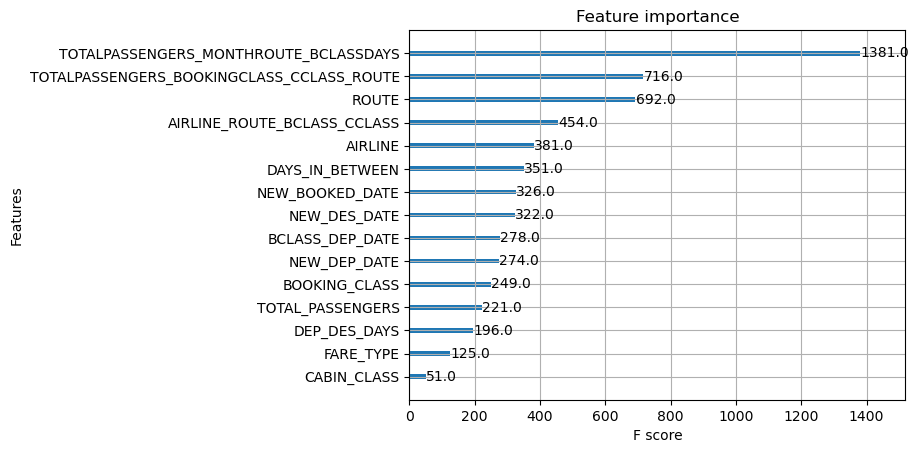

In [161]:
xgb.plot_importance(model)

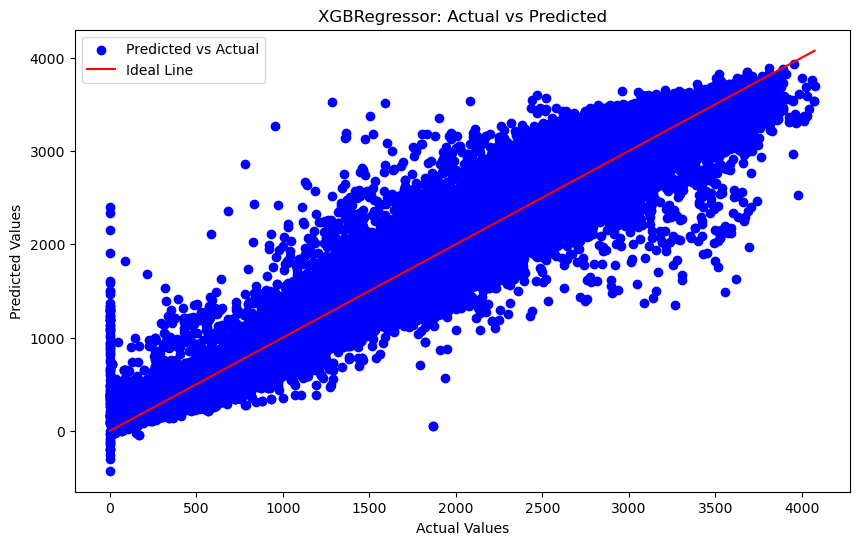

In [162]:
# Plotting
plt.figure(figsize=(10, 6))
plt.scatter(y_test, predictions, color="blue", label="Predicted vs Actual")
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color="red", label="Ideal Line")
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("XGBRegressor: Actual vs Predicted")
plt.legend()
plt.show()

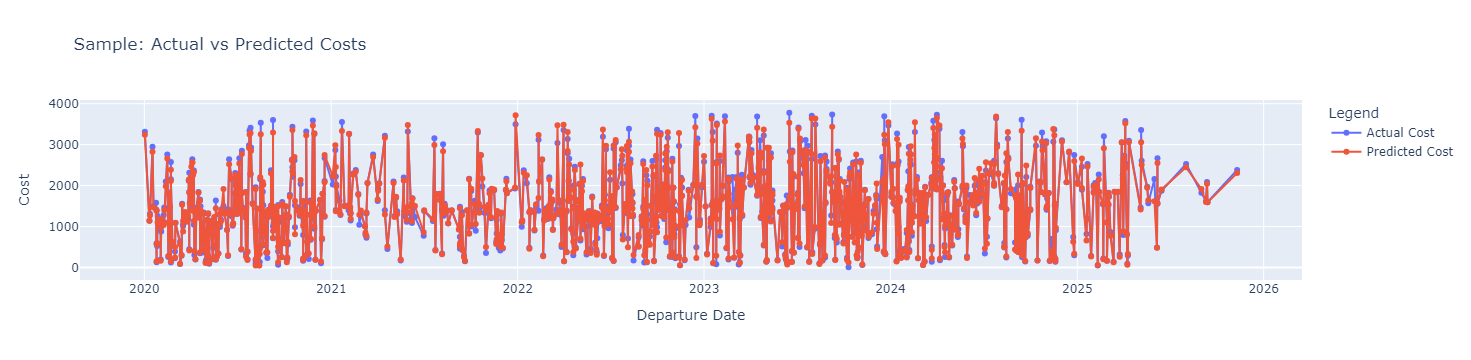

In [163]:
import plotly.graph_objects as go

# Create the interactive plot of Actual vs Predicted costs
test_df = X_test.copy()
test_df[target] = y_test
test_df['PREDICTED_COST'] = predictions
test_df['DEP_DATE'] = df.loc[X_test.index, 'DEP_DATE']

# Sample a subset of the test data for visualization
sample_df = test_df.sample(n=1000, random_state=1)  # Adjust sample size as needed
sample_df = sample_df.sort_values(by='DEP_DATE')
# Create the interactive plot
fig = go.Figure()

# Add Actual Cost trace
fig.add_trace(go.Scatter(
    x=sample_df['DEP_DATE'],
    y=sample_df[target],
    mode='lines+markers',
    name='Actual Cost'
))

# Add Predicted Cost trace
fig.add_trace(go.Scatter(
    x=sample_df['DEP_DATE'],
    y=sample_df['PREDICTED_COST'],
    mode='lines+markers',
    name='Predicted Cost'
))

# Update layout for better readability
fig.update_layout(
    title='Sample: Actual vs Predicted Costs',
    xaxis_title='Departure Date',
    yaxis_title='Cost',
    legend_title='Legend'
)

# Show the plot
fig.show()


In [164]:
# Assuming `model` is your trained XGBoost model
booster = model.get_booster()
importance = booster.get_score(importance_type='weight')

# Convert the importance dictionary to a sorted list of tuples
importance_sorted = sorted(importance.items(), key=lambda item: item[1], reverse=True)

# Print the feature importance values
for feature, score in importance_sorted:
    print(f"Feature: {feature}, Score: {score}")


Feature: TOTALPASSENGERS_MONTHROUTE_BCLASSDAYS, Score: 1381.0
Feature: TOTALPASSENGERS_BOOKINGCLASS_CCLASS_ROUTE, Score: 716.0
Feature: ROUTE, Score: 692.0
Feature: AIRLINE_ROUTE_BCLASS_CCLASS, Score: 454.0
Feature: AIRLINE, Score: 381.0
Feature: DAYS_IN_BETWEEN, Score: 351.0
Feature: NEW_BOOKED_DATE, Score: 326.0
Feature: NEW_DES_DATE, Score: 322.0
Feature: BCLASS_DEP_DATE, Score: 278.0
Feature: NEW_DEP_DATE, Score: 274.0
Feature: BOOKING_CLASS, Score: 249.0
Feature: TOTAL_PASSENGERS, Score: 221.0
Feature: DEP_DES_DAYS, Score: 196.0
Feature: FARE_TYPE, Score: 125.0
Feature: CABIN_CLASS, Score: 51.0


In [189]:
from datetime import date, timedelta

sample_booking = {
    'BOOKED_DATE': pd.Timestamp(date.today()),
    'DEP_DATE': '2024-10-11',
    'DES_DATE': '2024-10-16',
    'ADULT': 2,
    'CHILD': 0,
    'INFANT': 0,
    'CABIN_CLASS': 'economy',
    'FARE_TYPE': 'ITX',
    'BOOKING_CLASS': 'B',
    'ROUTE': 'LHR -> CMB -> CMB -> MLE -> MLE -> CMB -> CMB -> LHR',
    'AIRLINE': 'UL',
}

# Convert the sample booking into a DataFrame
sample_df = pd.DataFrame([sample_booking])


sample_df['BOOKED_DATE'] = pd.to_datetime(sample_df['BOOKED_DATE'])
sample_df['DEP_DATE'] = pd.to_datetime(sample_df['DEP_DATE'])

# Add 50 days to the booked date for prediction purposes
sample_df['BOOKED_DATE'] = sample_df['BOOKED_DATE'] + pd.Timedelta(days=50)

# Calculate DAYS_IN_BETWEEN for future predictions
sample_df['DAYS_IN_BETWEEN'] = (sample_df['DEP_DATE'] - sample_df['BOOKED_DATE']).dt.days
# Extract date components
sample_df['BOOKED_YEAR'] = sample_df['BOOKED_DATE'].dt.year
sample_df['BOOKED_MONTH'] = sample_df['BOOKED_DATE'].dt.month
sample_df['BOOKED_DAY'] = sample_df['BOOKED_DATE'].dt.day
sample_df['DEP_YEAR'] = sample_df['DEP_DATE'].dt.year
sample_df['DEP_MONTH'] = sample_df['DEP_DATE'].dt.month
sample_df['DEP_DAY'] = sample_df['DEP_DATE'].dt.day
sample_df['DES_DATE'] = pd.to_datetime(sample_df['DES_DATE'])
sample_df['DES_YEAR'] = sample_df['DES_DATE'].dt.year
sample_df['DES_MONTH'] = sample_df['DES_DATE'].dt.month
sample_df['DES_DAY'] = sample_df['DES_DATE'].dt.day
sample_df['DEP_DES_DAYS'] = (sample_df['DES_DATE'] - sample_df['DEP_DATE']).dt.days
sample_df['DAY_OF_WEEK'] = sample_df['DEP_DATE'].dt.dayofweek
sample_df['TOTAL_PASSENGERS'] = sample_df['ADULT'] + sample_df['CHILD'] + sample_df['INFANT']
sample_df['NEW_DEP_DATE'] = sample_df['DEP_YEAR'].astype(str) + '_' + sample_df['DEP_MONTH'].astype(str) + '_' + sample_df['DEP_DAY'].astype(str)
sample_df['NEW_DES_DATE'] = sample_df['DES_YEAR'].astype(str) + '_' + sample_df['DES_MONTH'].astype(str) + '_' + sample_df['DES_DAY'].astype(str)
sample_df['NEW_BOOKED_DATE'] = sample_df['BOOKED_YEAR'].astype(str) + '_' + sample_df['BOOKED_MONTH'].astype(str) + '_' + sample_df['BOOKED_DAY'].astype(str)
sample_df['BCLASS_DEP_DATE'] = sample_df['BOOKING_CLASS'].astype(str) + '_' + sample_df['DEP_DATE'].astype(str)
sample_df['AIRLINE_ROUTE_BCLASS_CCLASS'] = sample_df['AIRLINE'].astype(str) + '_' + sample_df['ROUTE'].astype(str) + '_' + sample_df['BOOKING_CLASS'].astype(str) + '_' + sample_df['CABIN_CLASS'].astype(str)
sample_df['BOOKING_CLASS_DAYS_IN_BETWEEN'] = sample_df['BOOKING_CLASS'].astype(str) + '_' + sample_df['DAYS_IN_BETWEEN'].astype(str)
sample_df['DEP_MONTH_ROUTE'] = sample_df['DEP_MONTH'].astype(str) + '_' + sample_df['ROUTE'].astype(str)
sample_df['MONTHROUTE_BCLASSDAYS'] = sample_df['DEP_MONTH_ROUTE'].astype(str) + '_' + sample_df['BOOKING_CLASS_DAYS_IN_BETWEEN'].astype(str)
sample_df['TOTALPASSENGERS_MONTHROUTE_BCLASSDAYS'] = sample_df['TOTAL_PASSENGERS'].astype(str) + '_' + sample_df['MONTHROUTE_BCLASSDAYS'].astype(str)
sample_df['TOTALPASSENGERS_BOOKINGCLASS_CCLASS_ROUTE'] = sample_df['TOTAL_PASSENGERS'].astype(str) + '_' + sample_df['BOOKING_CLASS'].astype(str) + '_' + sample_df['CABIN_CLASS'].astype(str) + '_' + sample_df['ROUTE'].astype(str)

# Apply the TargetEncoder to the target features (same as training)
sample_df[target_features] = encoder.transform(sample_df[target_features])

# Apply LabelEncoder to the label features (same as training)
for feature in label_features:
    le = label_encoders[feature]
    sample_df[feature] = sample_df[feature].apply(lambda x: le.transform([x])[0] if x in le.classes_ else -1)

# Prepare features for prediction
features = ['ROUTE','AIRLINE','BOOKING_CLASS','CABIN_CLASS','FARE_TYPE', 'NEW_BOOKED_DATE', 'NEW_DEP_DATE', 'NEW_DES_DATE','DEP_DES_DAYS','DAYS_IN_BETWEEN','TOTAL_PASSENGERS'
            ,'BCLASS_DEP_DATE', 'AIRLINE_ROUTE_BCLASS_CCLASS', 'TOTALPASSENGERS_MONTHROUTE_BCLASSDAYS', 'TOTALPASSENGERS_BOOKINGCLASS_CCLASS_ROUTE'
           ]

# Predict the cost for this single booking
predicted_cost = model.predict(sample_df[features])

sample_df['PREDICTED_COST'] = predicted_cost

print(sample_df[['DEP_DATE', 'PREDICTED_COST']])

    DEP_DATE  PREDICTED_COST
0 2024-10-11     1735.911377
